In [1]:
import pandas as pd

combined_overall = pd.read_parquet(
    "../dataset/combined/combined_overall.parquet"
)

In [2]:
from pathlib import Path

cams_path = Path("../dataset/CAMS AMCs NAVs 09052025/processed/products")
kfintech_path = Path("../dataset/Kfintech AMCs NAVs 09052025/processed/fcode_desc")

cams_files = list(cams_path.glob("*.parquet"))
kfintech_files = list(kfintech_path.glob("*.parquet"))

cams_metadata = pd.read_parquet("../dataset/CAMS AMCs NAVs 09052025/processed/product_metadata.parquet")
kfintech_metadata = pd.read_parquet("../dataset/Kfintech AMCs NAVs 09052025/processed/fcode_desc_metadata.parquet")

In [3]:
# CAMS
cams_check = combined_overall[
    combined_overall["source"] == "CAMS"
].merge(
    cams_metadata[["PRODCODE", "ISIN_NO"]],
    left_on="product_id",
    right_on="PRODCODE",
    how="left"
)

# KFINTECH
kfintech_meta_check = kfintech_metadata.copy()
kfintech_meta_check["FCODE_DESC_ID"] = (
    kfintech_meta_check["FCODE_DESC_ID"]
    .astype("string")
)

kfintech_check = combined_overall[
    combined_overall["source"] == "KFINTECH"
].merge(
    kfintech_meta_check[["FCODE_DESC_ID", "SCHEMEISIN"]],
    left_on="product_id",
    right_on="FCODE_DESC_ID",
    how="left"
)

# Check ISIN availability
cams_has_isin = (
    cams_check["ISIN_NO"].notna() &
    cams_check["ISIN_NO"].ne("")
)

kfintech_has_isin = (
    kfintech_check["SCHEMEISIN"].notna() &
    kfintech_check["SCHEMEISIN"].ne("")
)

print("CAMS")
print("Total:", len(cams_check))
print("Has ISIN:", cams_has_isin.sum())
print("Missing ISIN:", (~cams_has_isin).sum())

print("\nKFINTECH")
print("Total:", len(kfintech_check))
print("Has ISIN:", kfintech_has_isin.sum())
print("Missing ISIN:", (~kfintech_has_isin).sum())

print("\nOVERALL")
total = len(combined_overall)
has_isin = cams_has_isin.sum() + kfintech_has_isin.sum()

print("Total:", total)
print("Has ISIN:", has_isin)
print("Missing ISIN:", total - has_isin)
print(f"Coverage: {has_isin / total * 100:.2f}%")

CAMS
Total: 5314
Has ISIN: 5301
Missing ISIN: 13

KFINTECH
Total: 3762
Has ISIN: 3755
Missing ISIN: 7

OVERALL
Total: 9076
Has ISIN: 9056
Missing ISIN: 20
Coverage: 99.78%


In [4]:
# KFINTECH: product_id → parquet file
kfintech_map = {
    path.stem.split("-", 1)[0]: path
    for path in kfintech_files
}

# Get the parquet file for a product_id
def get_kfintech_file(product_id):
    return kfintech_map[str(product_id).zfill(6)]

In [5]:
# CAMS: product_id → parquet file
cams_map = {
    path.stem: path
    for path in cams_files
}

# Get the parquet file for a product_id
def get_cams_file(product_id):
    return cams_map[str(product_id)]

In [6]:
FINAL_COLUMNS = [
    "RTA",
    "product_id",
    "NAV_DATE",
    "NAV_VALUE",
    "name",
    "scheme",
    "isin"
]

In [7]:
def load_kfintech_product(product_id, start_date):
    file = get_kfintech_file(product_id)
    df = pd.read_parquet(file)

    # Normalize dates
    df["NAVDATE"] = pd.to_datetime(df["NAVDATE"])
    start_date = pd.to_datetime(start_date)

    # Filter from start date
    df = df[df["NAVDATE"] >= start_date]

    # Keep required NAV columns
    df = df[["FCODE_DESC_ID", "NAVDATE", "NAV"]].rename(columns={
        "NAVDATE": "NAV_DATE",
        "NAV": "NAV_VALUE"
    })

    # Load required metadata
    metadata = kfintech_metadata[
        [
            "FCODE_DESC_ID",
            "FCODE",
            "FUNDDESC",
            "SCHEME",
            "SCHEMEISIN"
        ]
    ].copy()

    # Match NAV data with metadata
    df = df.merge(
        metadata,
        on="FCODE_DESC_ID",
        how="left",
        validate="many_to_one"
    )

    # Create unique product ID
    df["product_id"] = (
        df["FCODE"].astype("string")
        + "_"
        + df["FCODE_DESC_ID"].astype("string")
    )

    # Rename metadata columns
    df = df.rename(columns={
        "FUNDDESC": "name",
        "SCHEME": "scheme",
        "SCHEMEISIN": "isin"
    })

    # Add RTA
    df["RTA"] = "KFINTECH"

    # Standardize dtypes
    df["RTA"] = df["RTA"].astype("string")
    df["product_id"] = df["product_id"].astype("string")
    df["NAV_DATE"] = (
        pd.to_datetime(df["NAV_DATE"])
        .astype("datetime64[us]")
    )
    df["NAV_VALUE"] = df["NAV_VALUE"].astype("float64")
    df["name"] = df["name"].astype("string")
    df["scheme"] = df["scheme"].astype("string")
    df["isin"] = df["isin"].astype("string")

    # Sort and remove duplicate NAV dates
    df = df.sort_values("NAV_DATE")
    df = df.drop_duplicates("NAV_DATE", keep="last")

    # Return final schema
    return df[FINAL_COLUMNS].reset_index(drop=True)

In [8]:
def load_cams_product(product_id, start_date):
    file = get_cams_file(product_id)
    df = pd.read_parquet(file)

    # Normalize dates
    df["NAV_DATE"] = pd.to_datetime(df["NAV_DATE"])
    start_date = pd.to_datetime(start_date)

    # Filter from start date
    df = df[df["NAV_DATE"] >= start_date]

    # Keep required NAV columns
    df = df[["NAV_DATE", "NAV_VALUE"]].copy()

    # Add product ID
    df.insert(0, "product_id", str(product_id))

    # Load required metadata
    metadata = cams_metadata[
        [
            "PRODCODE",
            "NAME",
            "SCHEME_TYP",
            "ISIN_NO"
        ]
    ].copy()

    # Match NAV data with metadata
    df = df.merge(
        metadata,
        left_on="product_id",
        right_on="PRODCODE",
        how="left",
        validate="many_to_one"
    )

    # Rename metadata columns
    df = df.rename(columns={
        "NAME": "name",
        "SCHEME_TYP": "scheme",
        "ISIN_NO": "isin"
    })

    # Add RTA
    df["RTA"] = "CAMS"

    # Standardize dtypes
    df["RTA"] = df["RTA"].astype("string")
    df["product_id"] = df["product_id"].astype("string")
    df["NAV_DATE"] = pd.to_datetime(df["NAV_DATE"])
    df["NAV_VALUE"] = df["NAV_VALUE"].astype("float64")
    df["name"] = df["name"].astype("string")
    df["scheme"] = df["scheme"].astype("string")
    df["isin"] = df["isin"].astype("string")

    # Sort and remove duplicate NAV dates
    df = df.sort_values("NAV_DATE")
    df = df.drop_duplicates("NAV_DATE", keep="last")

    # Return final schema
    return df[FINAL_COLUMNS].reset_index(drop=True)

In [9]:
def load_product(record):
    if record["source"] == "CAMS":
        return load_cams_product(
            record["product_id"],
            record["start_date"]
        )
    
    elif record["source"] == "KFINTECH":
        return load_kfintech_product(
            record["product_id"],
            record["start_date"]
        )
    
    else:
        raise ValueError(f"Unknown source: {record['source']}")

In [10]:
output_dir = Path("../dataset/combined")
products_dir = output_dir / "products"

output_dir.mkdir(parents=True, exist_ok=True)
products_dir.mkdir(parents=True, exist_ok=True)

all_products = []
successful = 0
failed = 0

records = combined_overall.to_dict("records")

for i, record in enumerate(records, start=1):
    try:
        df = load_product(record)

        # Product ID from final standardized dataframe
        product_id = str(df["product_id"].iloc[0])

        # Save individual product
        output_path = products_dir / f"{product_id}.parquet"
        df.to_parquet(output_path, index=False)

        # Keep for final combined dataframe
        all_products.append(df)

        successful += 1

        if i % 100 == 0:
            print(f"Processed {i:,} / {len(records):,}")

    except Exception as e:
        failed += 1
        print(
            f"Failed: {record['source']} - "
            f"{record['product_id']} - {e}"
        )

# Combine everything
final_df = pd.concat(
    all_products,
    ignore_index=True
)

# Save combined dataframe
combined_path = output_dir / "final_combined.parquet"
final_df.to_parquet(combined_path, index=False)

print("\nCompleted")
print("Successful:", successful)
print("Failed:", failed)
print("Final shape:", final_df.shape)
print("Combined file:", combined_path)

Processed 100 / 9,076
Processed 200 / 9,076
Processed 300 / 9,076
Processed 400 / 9,076
Processed 500 / 9,076
Processed 600 / 9,076
Processed 700 / 9,076
Processed 800 / 9,076
Processed 900 / 9,076
Processed 1,000 / 9,076
Processed 1,100 / 9,076
Processed 1,200 / 9,076
Processed 1,300 / 9,076
Processed 1,400 / 9,076
Processed 1,500 / 9,076
Processed 1,600 / 9,076
Processed 1,700 / 9,076
Processed 1,800 / 9,076
Processed 1,900 / 9,076
Processed 2,000 / 9,076
Processed 2,100 / 9,076
Processed 2,200 / 9,076
Processed 2,300 / 9,076
Processed 2,400 / 9,076
Processed 2,500 / 9,076
Processed 2,600 / 9,076
Processed 2,700 / 9,076
Processed 2,800 / 9,076
Processed 2,900 / 9,076
Processed 3,000 / 9,076
Processed 3,100 / 9,076
Processed 3,200 / 9,076
Processed 3,300 / 9,076
Processed 3,400 / 9,076
Processed 3,500 / 9,076
Processed 3,600 / 9,076
Processed 3,700 / 9,076
Processed 3,800 / 9,076
Processed 3,900 / 9,076
Processed 4,000 / 9,076
Processed 4,100 / 9,076
Processed 4,200 / 9,076
Processed 

In [11]:
target_return = 0.07

return_data = []

product_files = list(products_dir.glob("*.parquet"))

for i, file in enumerate(product_files, start=1):
    df = pd.read_parquet(file)

    df = df.sort_values("NAV_DATE")

    # Basic information
    rta = df["RTA"].iloc[0]
    product_id = df["product_id"].iloc[0]

    # Dates
    start_date = df["NAV_DATE"].iloc[0]
    end_date = df["NAV_DATE"].iloc[-1]

    # Duration
    duration_days = (end_date - start_date).days
    duration_years = int(duration_days // 365.25)

    # NAVs
    first_nav = df["NAV_VALUE"].iloc[0]
    last_nav = df["NAV_VALUE"].iloc[-1]

    # Total return
    total_return_pct = (
        (last_nav - first_nav) / first_nav
    ) * 100

    # Annualized return
    annualized_return_pct = (
        (last_nav / first_nav) ** (
            1 / max(duration_years, 1)
        ) - 1
    ) * 100

    # Daily returns
    daily_returns = df["NAV_VALUE"].pct_change().dropna()

    # Downside volatility
    negative_returns = daily_returns[
        daily_returns < target_return / 252
    ]

    downside_volatility = (
        negative_returns.std()
        * (252 ** 0.5)
        * 100
        if len(negative_returns) > 1
        else pd.NA
    )

    # Maximum drawdown
    cumulative_max = df["NAV_VALUE"].cummax()

    drawdown = (
        (df["NAV_VALUE"] - cumulative_max)
        / cumulative_max
    ) * 100

    max_drawdown_pct = drawdown.min()

    # Sortino ratio
    sortino_ratio = (
        (annualized_return_pct / 100 - target_return)
        / (downside_volatility / 100)
        if pd.notna(downside_volatility)
        and downside_volatility > 0
        else pd.NA
    )

    # Calendar-year returns
    yearly_nav = (
        df.set_index("NAV_DATE")["NAV_VALUE"]
        .resample("YE")
        .agg(["first", "last"])
    )

    yearly_returns = (
        (yearly_nav["last"] / yearly_nav["first"]) - 1
    ) * 100

    best_year_return_pct = (
        yearly_returns.max()
        if len(yearly_returns) > 0
        else pd.NA
    )

    worst_year_return_pct = (
        yearly_returns.min()
        if len(yearly_returns) > 0
        else pd.NA
    )

    # Store product metrics
    return_data.append({
        "RTA": rta,
        "product_id": product_id,
        "start_date": start_date,
        "end_date": end_date,
        "duration_years": duration_years,
        "total_return_pct": total_return_pct,
        "annualized_return_pct": annualized_return_pct,
        "best_year_return_pct": best_year_return_pct,
        "worst_year_return_pct": worst_year_return_pct,
        "max_drawdown_pct": max_drawdown_pct,
        "downside_volatility": downside_volatility,
        "sortino_ratio": sortino_ratio
    })

    if i % 500 == 0:
        print(f"Processed {i:,} / {len(product_files):,}")

returns_df = pd.DataFrame(return_data)

Processed 500 / 9,076
Processed 1,000 / 9,076
Processed 1,500 / 9,076
Processed 2,000 / 9,076
Processed 2,500 / 9,076
Processed 3,000 / 9,076
Processed 3,500 / 9,076
Processed 4,000 / 9,076
Processed 4,500 / 9,076
Processed 5,000 / 9,076
Processed 5,500 / 9,076
Processed 6,000 / 9,076
Processed 6,500 / 9,076
Processed 7,000 / 9,076
Processed 7,500 / 9,076
Processed 8,000 / 9,076
Processed 8,500 / 9,076
Processed 9,000 / 9,076


In [12]:
returns_df = returns_df.sort_values(
    "best_year_return_pct",
    ascending=False
).reset_index(drop=True)

In [13]:
returns_df

,RTA,product_id,start_date,end_date,duration_years,total_return_pct,annualized_return_pct,best_year_return_pct,worst_year_return_pct,max_drawdown_pct,downside_volatility,sortino_ratio
0,CAMS,FTI025,1998-08-10,2025-05-09,26,4787.323711,16.135307,479.666402,-71.903052,-90.827603,24.266045,0.376465
1,CAMS,FTI026P,1998-08-10,2025-05-09,26,357.106186,6.019383,422.875298,-78.706468,-93.044780,27.702492,-0.035398
2,CAMS,FTI026,1998-08-10,2025-05-09,26,357.106186,6.019383,422.875298,-78.706468,-93.044780,27.702492,-0.035398
3,CAMS,B02,1996-03-31,2025-05-09,29,1711.800000,10.505301,290.004462,-71.933600,-83.450874,24.514966,0.142986
4,CAMS,B201D,1995-02-24,2025-05-09,30,1198.100000,8.920662,283.758151,-60.864329,-76.490344,20.623766,0.093129
...,...,...,...,...,...,...,...,...,...,...,...,...
9071,KFINTECH,178ONID_12364,2019-04-25,2025-05-11,6,0.000180,0.000030,0.000180,-0.000020,-0.011589,0.006527,-1072.390462
9072,CAMS,FTI865,2019-05-08,2025-05-09,6,0.000080,0.000013,0.000080,0.000000,-0.058336,0.031123,-224.914589
9073,KFINTECH,117ONRD_5754,2019-10-15,2025-05-11,5,0.000040,0.000008,0.000070,-0.000020,-0.003050,0.001269,-5517.135204
9074,CAMS,FTI863,2019-05-08,2025-05-09,6,0.000010,0.000002,0.000010,0.000000,-0.058036,0.030903,-226.511918


In [14]:
count = (returns_df["annualized_return_pct"] >= 14).sum()

print(count)

2209


In [15]:
returns_df.to_parquet(
    output_dir / "returns.parquet",
    index=False
)

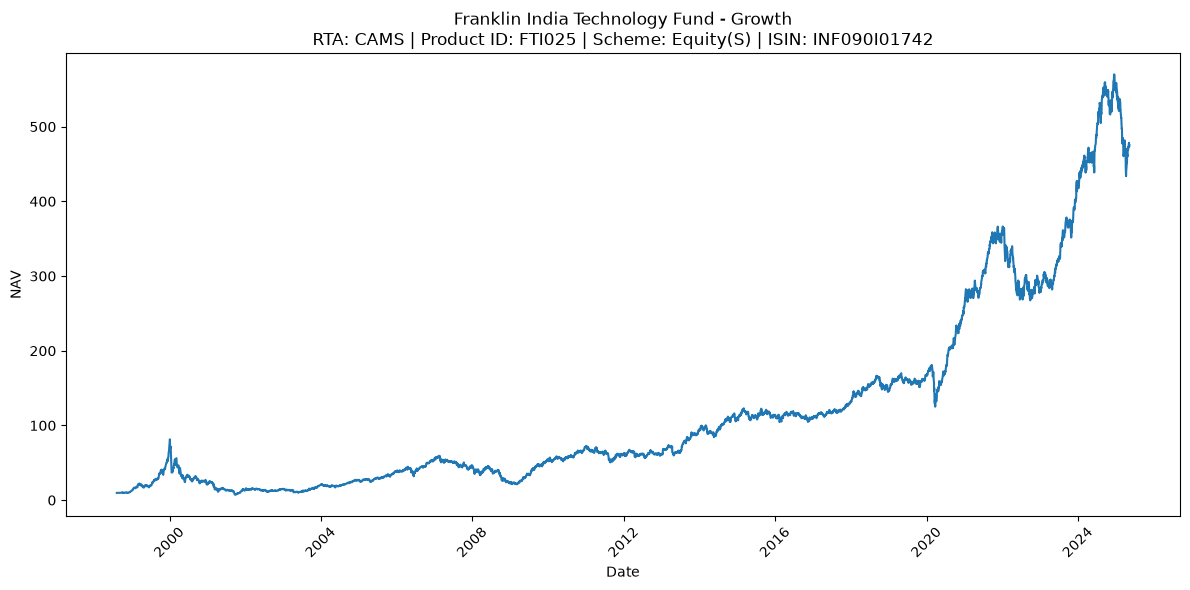

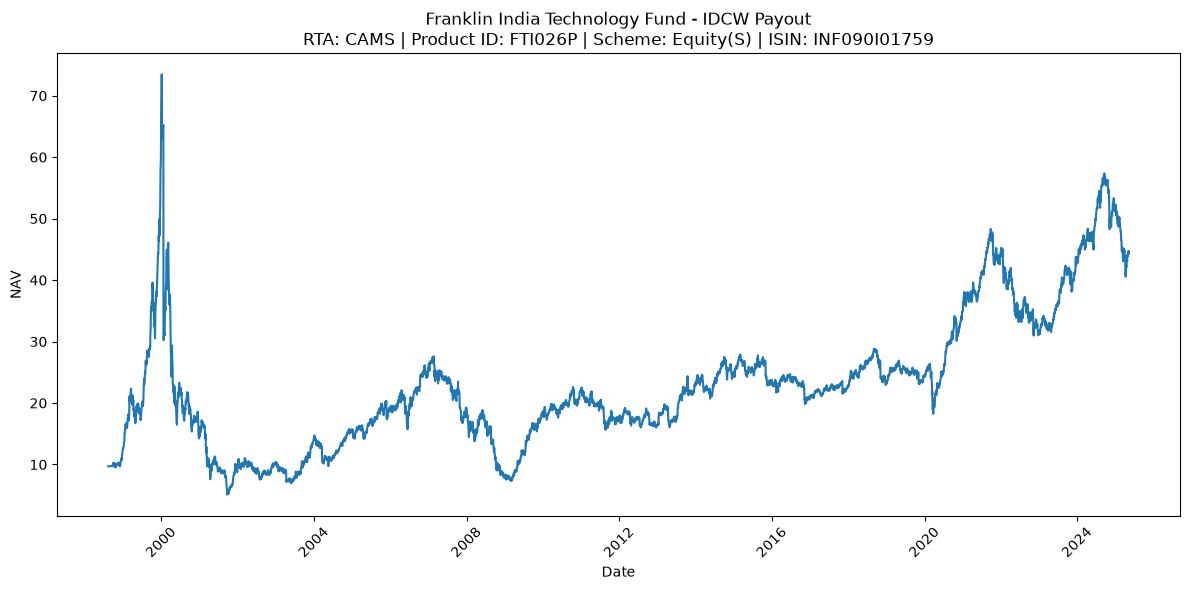

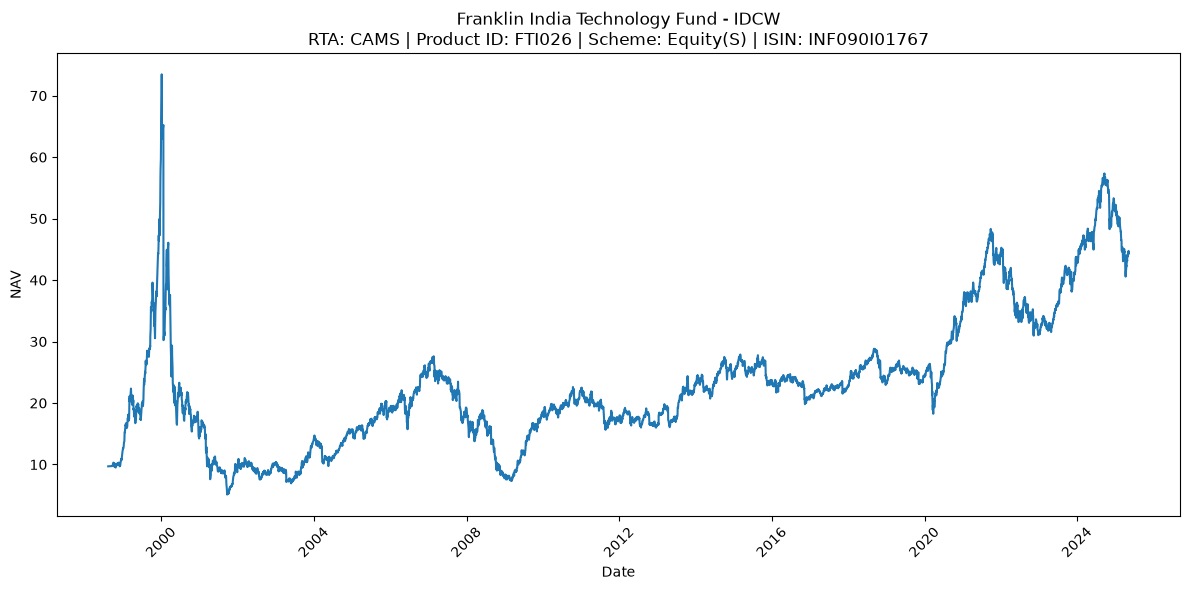

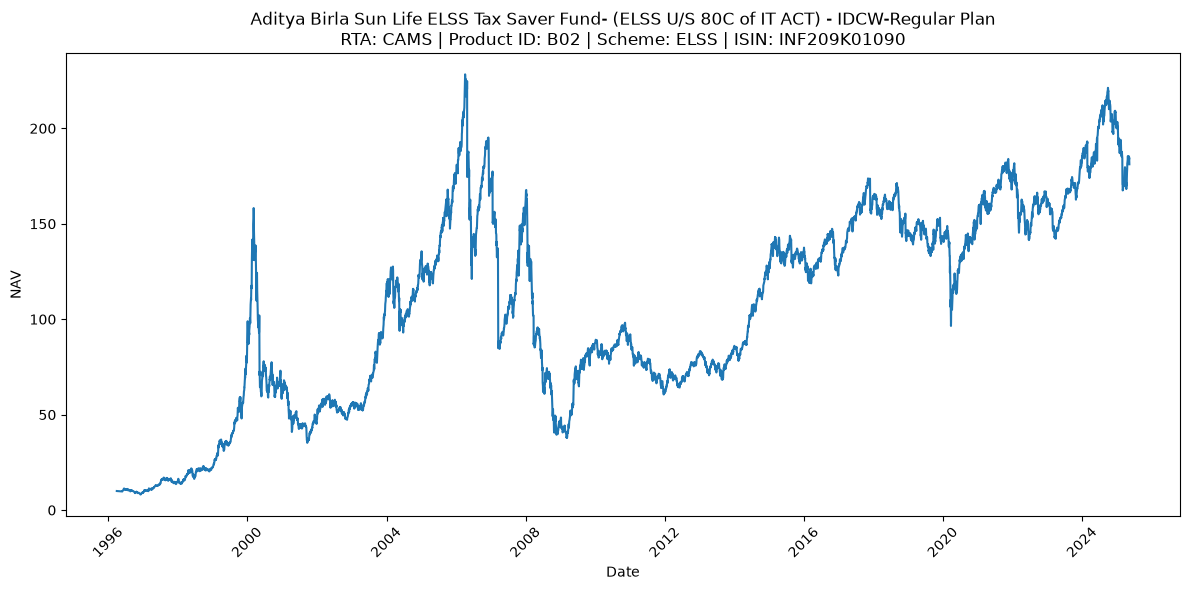

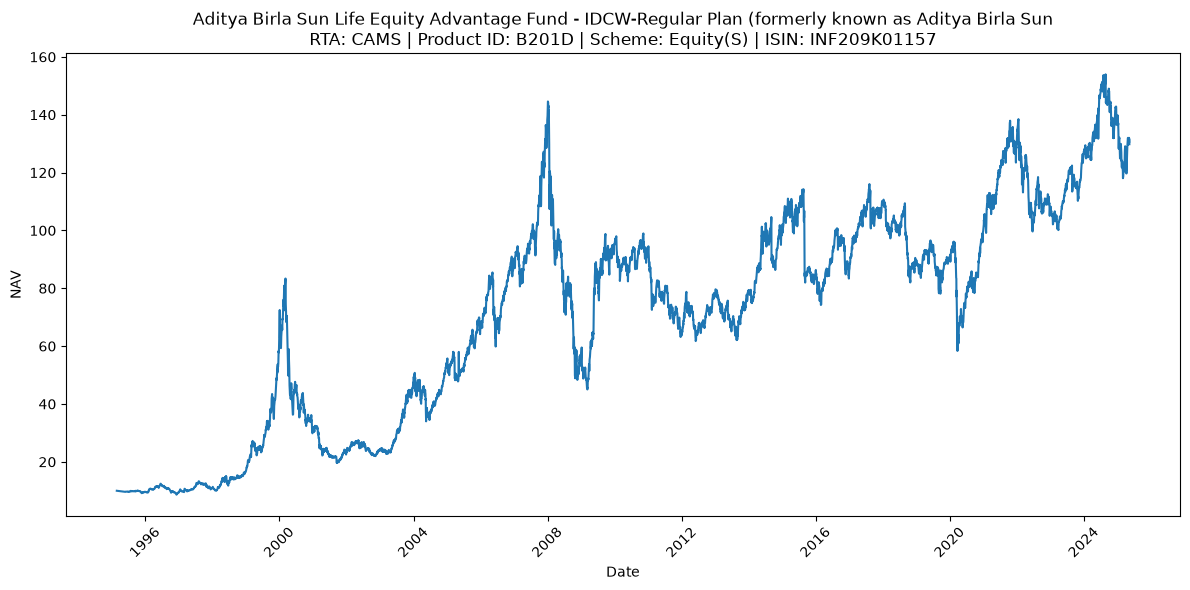

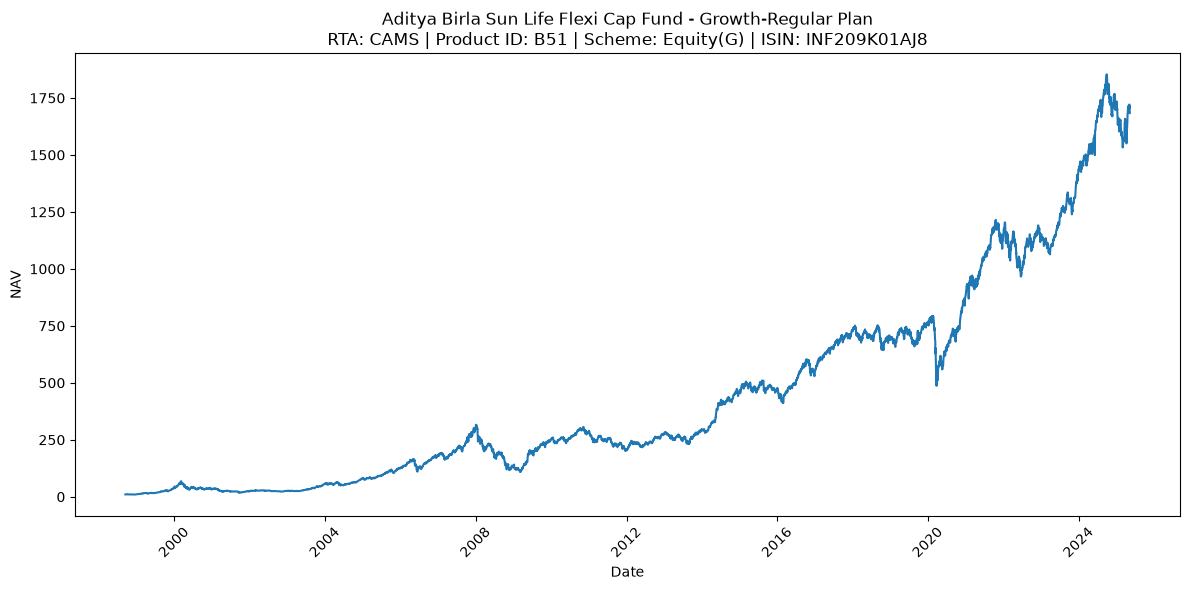

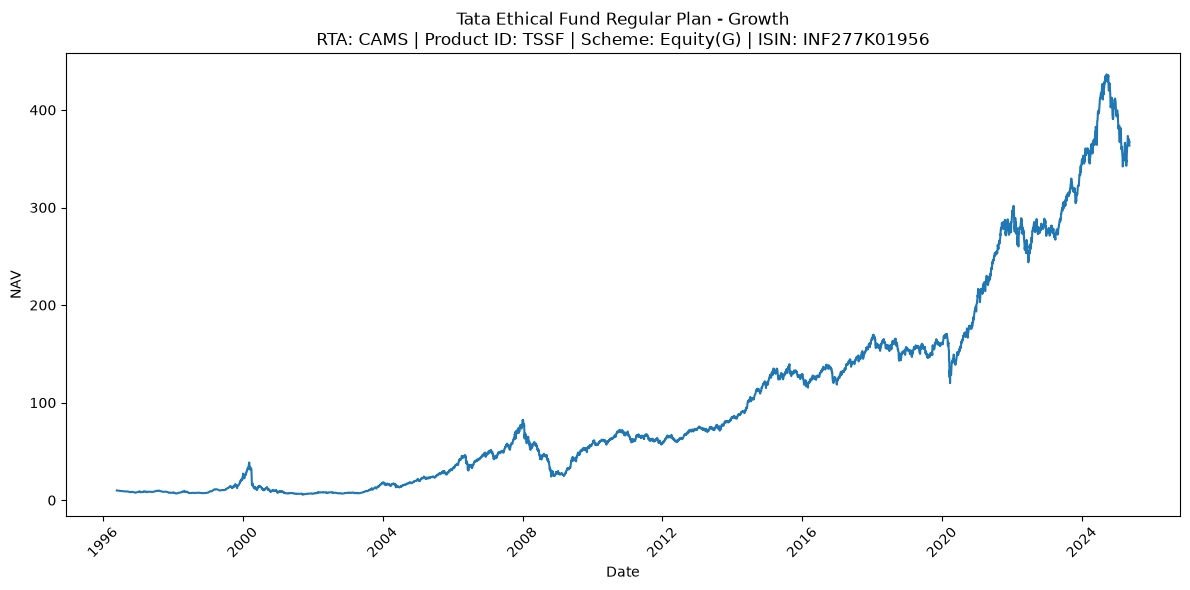

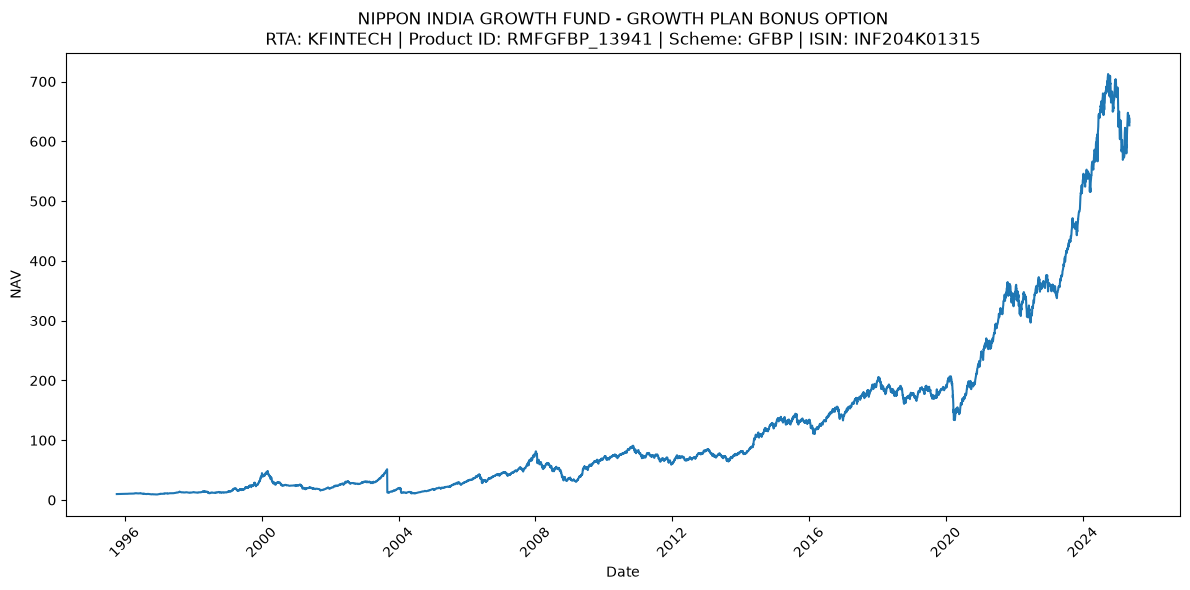

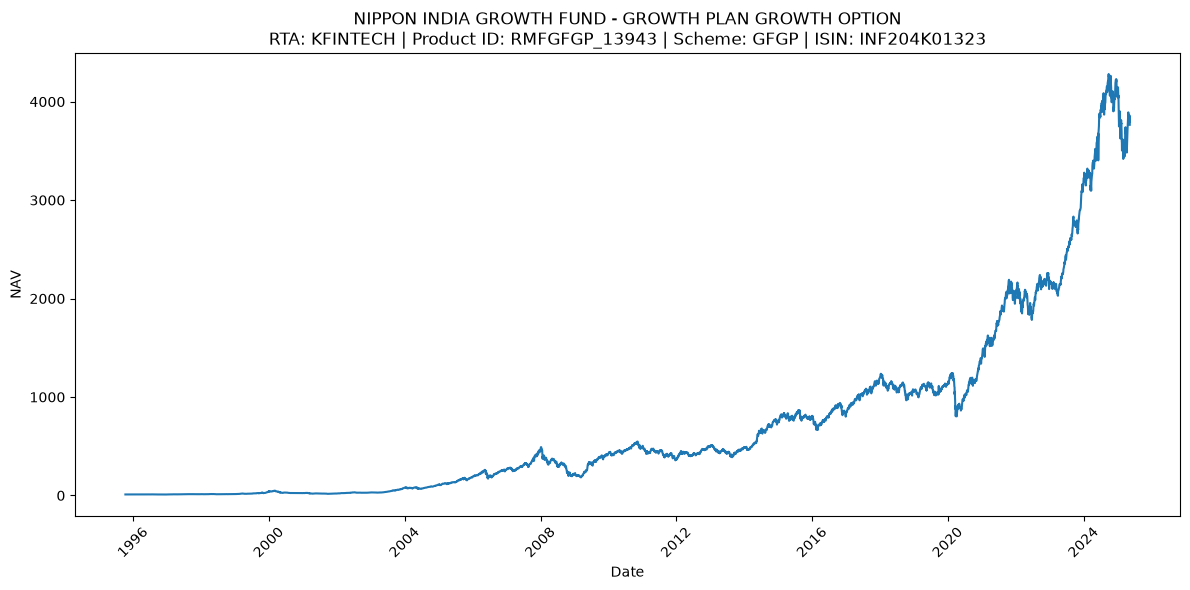

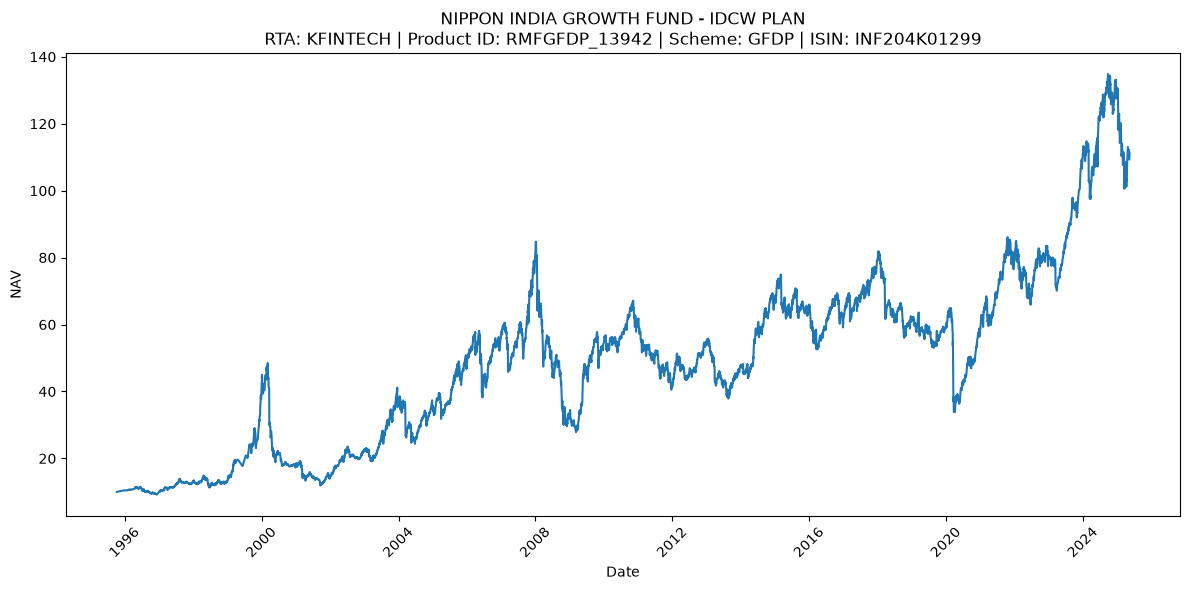

In [16]:
import matplotlib.pyplot as plt

x = 10

top_products = returns_df.head(x)["product_id"].tolist()

for product_id in top_products:

    data = final_df[
        final_df["product_id"] == product_id
    ].sort_values("NAV_DATE")

    details = data.iloc[0]

    title = (
        f"{details['name']}\n"
        f"RTA: {details['RTA']} | "
        f"Product ID: {details['product_id']} | "
        f"Scheme: {details['scheme']} | "
        f"ISIN: {details['isin']}"
    )

    plt.figure(figsize=(12, 6))

    plt.plot(
        data["NAV_DATE"],
        data["NAV_VALUE"]
    )

    plt.xlabel("Date")
    plt.ylabel("NAV")
    plt.title(title)

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()